# Milestone 4: RFM Scoring and Customer Segmentation
**Objective:** Bin RFM features into quantile-based scores, define 4 distinct customer segments, and profile each segment by customer count, spend distribution, and revenue share.

In [1]:
import ssl
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pg8000

# 1. Establish secure SSL connection
ssl_context = ssl.create_default_context()
ssl_context.check_hostname = False
ssl_context.verify_mode = ssl.CERT_NONE

conn = pg8000.connect(
    user="ecom_ro_user",
    password="work-experience-read-only",
    host="ep-bold-hall-azhf2f45-pooler.c-3.ap-southeast-1.aws.neon.tech",
    database="neondb",
    port=5432,
    ssl_context=ssl_context
)

# 2. Extract customer-level RFM metrics
rfm_query = """
WITH max_date AS (
    SELECT MAX(created_at::date) + INTERVAL '1 day' AS ref_date
    FROM ecom.orders
)
SELECT 
    customer_id,
    (SELECT ref_date FROM max_date)::date - MAX(created_at::date) AS recency_days,
    COUNT(order_id) AS frequency,
    SUM(total) AS monetary
FROM ecom.orders
GROUP BY customer_id;
"""

df_rfm = pd.read_sql(rfm_query, con=conn)
print(f"Loaded RFM records for {len(df_rfm):,} customers.")
df_rfm.head()

Loaded RFM records for 8,800 customers.


,customer_id,recency_days,frequency,monetary
0,6114,16,1,4835.64
1,4790,74,2,14033.74
2,273,43,1,3065.64
3,3936,72,5,41818.02
4,5761,44,6,51488.12


### 2. Quantile Scoring (R, F, M)
* **Recency Score (1–5):** Lower recency_days = higher score (5 = most recent).
* **Frequency Handling:** Frequency is heavily right-skewed with single-order customers. To handle duplicate bin edges cleanly, we use `rank(method='first')` before binning into quintiles.
* **Monetary Score (1–5):** Higher lifetime spend = higher score (5 = highest spend).

In [2]:
# 1. Calculate R, F, M scores (1 to 5)
df_rfm['r_score'] = pd.qcut(df_rfm['recency_days'], q=5, labels=[5, 4, 3, 2, 1]).astype(int)
df_rfm['f_score'] = pd.qcut(df_rfm['frequency'].rank(method='first'), q=5, labels=[1, 2, 3, 4, 5]).astype(int)
df_rfm['m_score'] = pd.qcut(df_rfm['monetary'], q=5, labels=[1, 2, 3, 4, 5]).astype(int)

# 2. Combined RFM Score string
df_rfm['rfm_cell'] = df_rfm['r_score'].astype(str) + df_rfm['f_score'].astype(str) + df_rfm['m_score'].astype(str)
df_rfm['rfm_score_sum'] = df_rfm['r_score'] + df_rfm['f_score'] + df_rfm['m_score']

# 3. Rule-Based Segment Mapping
def assign_segment(row):
    r, f, m = row['r_score'], row['f_score'], row['m_score']
    
    # VIP Champions: High spend & frequent buyers who bought recently
    if r >= 4 and f >= 4 and m >= 4:
        return 'VIP Champions'
    # Loyal Regulars: Moderate to high frequency/spend, active recency
    elif r >= 3 and (f >= 3 or m >= 3):
        return 'Loyal Regulars'
    # At-Risk / Churn Warning: Previously active high-value spenders slipping away
    elif r <= 2 and (f >= 3 or m >= 3):
        return 'At-Risk Spenders'
    # One-Time / Casual Buyers: Low frequency/spend or inactive
    else:
        return 'Casual & One-Timers'

df_rfm['segment'] = df_rfm.apply(assign_segment, axis=1)

# Check segment counts
df_rfm['segment'].value_counts()

Casual & One-Timers    2367
Loyal Regulars         2238
At-Risk Spenders       2214
VIP Champions          1981
Name: segment, dtype: int64

### 3. Segment Profiling & Revenue Contribution
Now we evaluate each segment by total customer count, percentage of customer base, percentage of total revenue, and average RFM metrics.

In [3]:
total_revenue = df_rfm['monetary'].sum()
total_customers = len(df_rfm)

segment_profile = df_rfm.groupby('segment').agg(
    customer_count=('customer_id', 'count'),
    total_segment_revenue=('monetary', 'sum'),
    avg_recency=('recency_days', 'mean'),
    avg_frequency=('frequency', 'mean'),
    avg_monetary=('monetary', 'mean')
).reset_index()

segment_profile['pct_customers'] = (segment_profile['customer_count'] / total_customers) * 100
segment_profile['pct_revenue'] = (segment_profile['total_segment_revenue'] / total_revenue) * 100

# Format and rearrange columns
segment_profile = segment_profile.sort_values(by='total_segment_revenue', ascending=False)
display(segment_profile[['segment', 'customer_count', 'pct_customers', 'pct_revenue', 'avg_recency', 'avg_frequency', 'avg_monetary']])

,segment,customer_count,pct_customers,pct_revenue,avg_recency,avg_frequency,avg_monetary
3,VIP Champions,1981,22.511364,65.854685,12.270570,13.021201,99315.295921
2,Loyal Regulars,2238,25.431818,17.391801,25.807417,3.070599,23216.589777
0,At-Risk Spenders,2214,25.159091,14.270051,66.117435,2.242999,19255.811987
1,Casual & One-Timers,2367,26.897727,2.483463,47.886354,1.000000,3134.537085


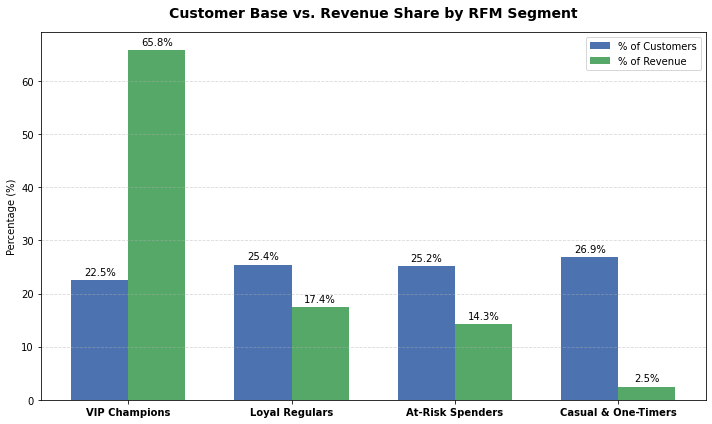

In [4]:
import matplotlib.pyplot as plt
import numpy as np

# Segment summary data from Milestone 4
segments = ['VIP Champions', 'Loyal Regulars', 'At-Risk Spenders', 'Casual & One-Timers']
pct_customers = [22.51, 25.43, 25.16, 26.90]
pct_revenue = [65.85, 17.39, 14.27, 2.48]

x = np.arange(len(segments))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))
rects1 = ax.bar(x - width/2, pct_customers, width, label='% of Customers', color='#4C72B0')
rects2 = ax.bar(x + width/2, pct_revenue, width, label='% of Revenue', color='#55A868')

ax.set_ylabel('Percentage (%)')
ax.set_title('Customer Base vs. Revenue Share by RFM Segment', fontsize=14, fontweight='bold', pad=15)
ax.set_xticks(x)
ax.set_xticklabels(segments, fontweight='semibold')
ax.legend(frameon=True)
ax.grid(axis='y', linestyle='--', alpha=0.5)

# Add value labels on top of bars
def autolabel(rects):
    for rect in rects:
        height = rect.get_height()
        ax.annotate(f'{height:.1f}%',
                    xy=(rect.get_x() + rect.get_width() / 2, height),
                    xytext=(0, 3),  # 3 points vertical offset
                    textcoords="offset points",
                    ha='center', va='bottom', fontsize=10)

autolabel(rects1)
autolabel(rects2)

plt.tight_layout()
# Save image to repo
plt.savefig('rfm_revenue_concentration.png', dpi=300)
plt.show()